In [17]:
from sklearn.datasets import make_classification
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from lda import lda_fit_svd, lda_predict

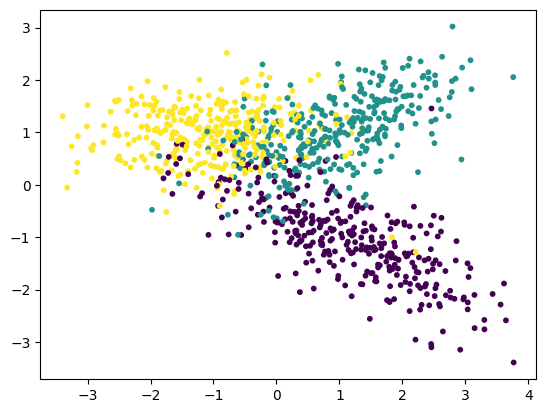

In [23]:
X, y = make_classification(
    n_samples=1000, n_features=2, n_informative=2, n_redundant=0, n_repeated=0, n_classes=3, n_clusters_per_class=1,
    random_state=0,
)
# X[:, 0][y == 0] += 4
# X[:, 1][y == 1] += 4
plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, s=10)
plt.show()

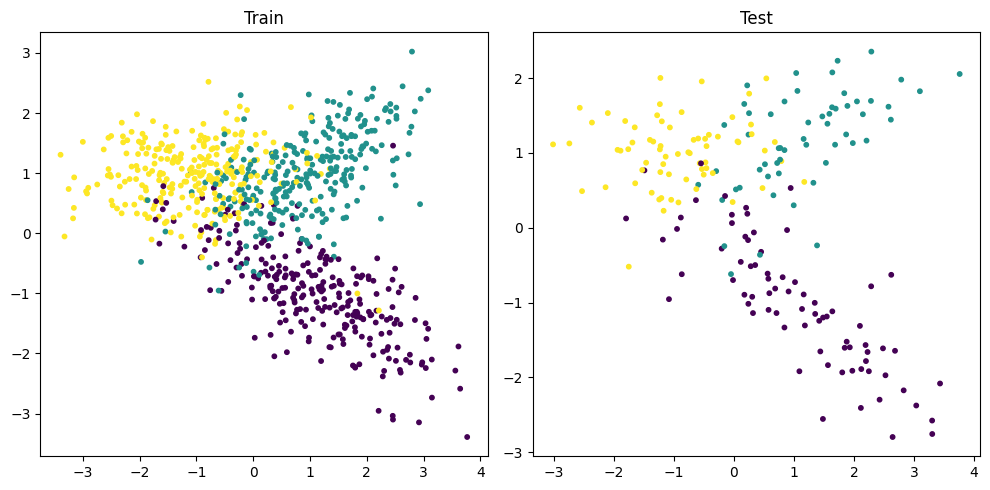

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=10)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=10)

axes[0].set_title("Train")
axes[1].set_title("Test")
fig.tight_layout()
plt.show()

In [27]:
sphere, discriminants = lda_fit_svd(X_train, y_train, [0, 1, 2])
y_pred = [lda_predict(x, sphere, discriminants) for x in X_test]
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.83


In [28]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred = lda.predict(X_test)
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.83


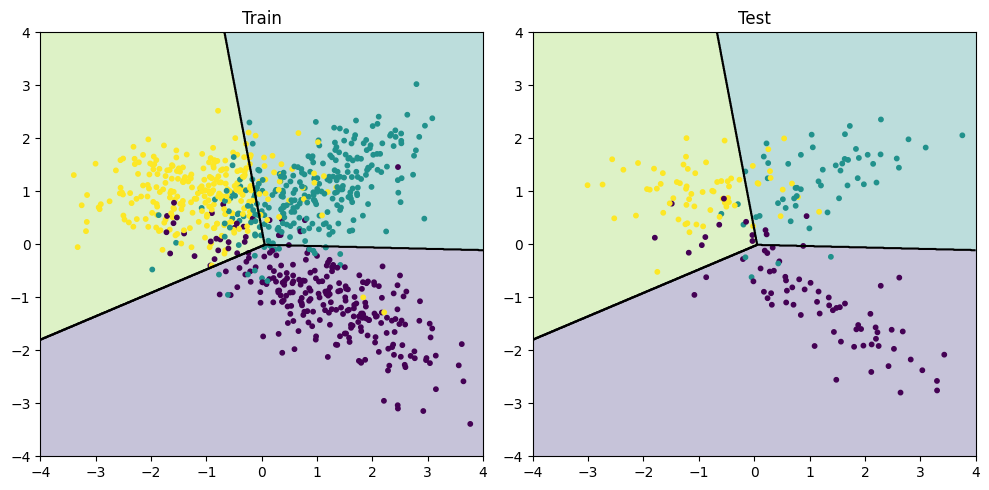

In [44]:
xv, yv = np.meshgrid(np.linspace(-4, 4, 1000), np.linspace(-4, 4, 1000))
Z = lda.decision_function(np.c_[xv.ravel(), yv.ravel()]).argmax(axis=1).reshape(xv.shape)

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 2, 1)
ax.contourf(xv, yv, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap='viridis', alpha=0.3)
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=10)
ax.contour(xv, yv, Z, levels=[0.5, 1.5], colors='k')
ax.set_title("Train")

ax = fig.add_subplot(1, 2, 2)
ax.contourf(xv, yv, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap='viridis', alpha=0.3)
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=10)
ax.contour(xv, yv, Z, levels=[0.5, 1.5], colors='k')
ax.set_title("Test")

fig.tight_layout()
plt.show()